# 04 · LSTM v1

The LSTM gets the same input as the baselines: a window of hourly returns of all 10 tickers.
It reads the window **one hour at a time**, updating a hidden state `h` (16 numbers), its running summary of
"what happened so far". After the last hour, a linear layer turns `h` into the prediction.

```
hour t-W+1 ──▶ [LSTM cell] ──▶ [LSTM cell] ──▶ ... ──▶ [LSTM cell] ──▶ h ──▶ linear ──▶ ICHR next hour
                 ▲ h, c          ▲ h, c                    ▲
              returns         returns                 returns at t
```

Question for this notebook: **does a longer memory help?** Window = 7 hours (1 day), 35 (1 week), 140 (4 weeks).
The bar from notebook 03: skill > 0 vs "always predict 0", in both 2025 and 2026.

Code: `src/semiconductor_affairs/lstm.py` (model + training loop).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from semiconductor_affairs.baselines import Zero, ridge
from semiconductor_affairs.data import load_close, log_returns
from semiconductor_affairs.evaluate import metrics, report, walk_forward, walk_forward_splits
from semiconductor_affairs.features import Dataset, make_dataset
from semiconductor_affairs.lstm import LSTMRegressor

r = log_returns(load_close())
WINDOWS = [7, 35, 140]
SEEDS = [0, 1, 2]

# Longer windows need more history before the first sample. Keep only the
# timestamps every window has, so all models are scored on the same hours.
raw = {w: make_dataset(r, window=w) for w in WINDOWS}
common = raw[max(WINDOWS)].timestamps

def restrict(d: Dataset) -> Dataset:
    keep = np.isin(d.timestamps, common)
    return Dataset(d.X[keep], d.y[keep], d.timestamps[keep], d.feature_names)

data = {w: restrict(d) for w, d in raw.items()}
splits = walk_forward_splits(common)
for w, d in data.items():
    print(f"window {w:3d}: X {d.X.shape}")

window   7: X (4103, 7, 10)
window  35: X (4103, 35, 10)
window 140: X (4103, 140, 10)


## How big is the model?
Each LSTM cell has 4 gates (input, forget, cell candidate, output). Each gate is a small linear layer on
`[input at this hour, previous h]`. With 10 inputs and 16 hidden units:
`4 × 16 × (10 + 16 + 1) ≈ 1,700` weights, plus 17 for the output layer. **The same weights are reused at every hour**,
so a 140-hour window doesn't need more weights than a 7-hour one.

In [2]:
m = LSTMRegressor()
m.fit(data[7].X[:500], data[7].y[:500])   # tiny fit just to build the network
print(m.net)
print("weights:", sum(p.numel() for p in m.net.parameters()))

LSTMNet(
  (lstm): LSTM(10, 16, batch_first=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (head): Linear(in_features=16, out_features=1, bias=True)
)
weights: 1809


## One fold up close: training curves
Train on everything before 2025-10-01 (fold 3). The last 20% of that training period is held out as **validation**:
the model never trains on it, and we stop when it stops improving there (**early stopping**), then keep the weights
of the best epoch.

Losses are in units of the target's variance, so **1.0 ≈ the loss of predicting 0**.

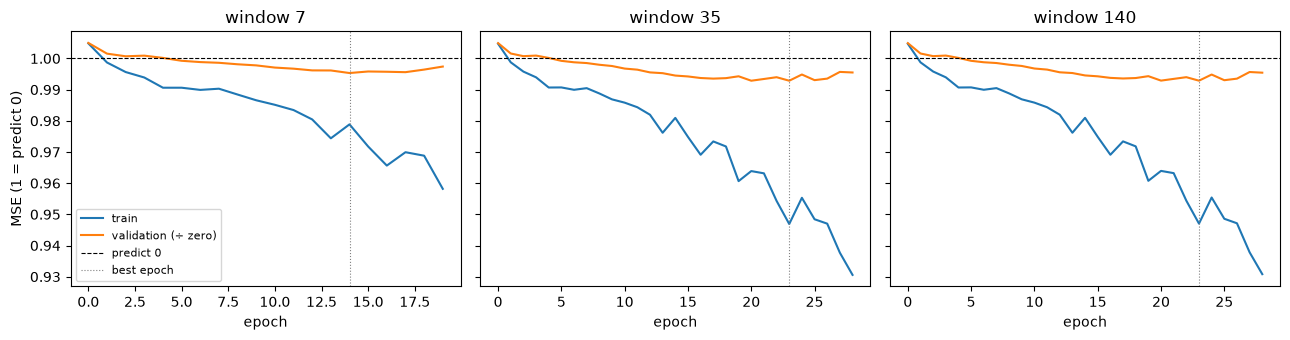

In [3]:
fold = 3
train, test = splits[fold]
fig, axes = plt.subplots(1, len(WINDOWS), figsize=(13, 3.5), sharey=True)
for ax, w in zip(axes, WINDOWS):
    m = LSTMRegressor(seed=0).fit(data[w].X[train], data[w].y[train])
    h = pd.DataFrame(m.history)
    ax.plot(h["train"], label="train")
    ax.plot(h["val"] / h["val_zero"], label="validation (÷ zero)")
    ax.axhline(1, color="k", lw=0.8, ls="--", label="predict 0")
    ax.axvline(h["val"].idxmin(), color="grey", lw=0.8, ls=":", label="best epoch")
    ax.set_title(f"window {w}")
    ax.set_xlabel("epoch")
axes[0].set_ylabel("MSE (1 = predict 0)")
axes[0].legend(fontsize=8)
plt.tight_layout()

**Reading the curves:** training loss keeps falling (the model memorises the training hours), while validation hovers
just below 1, i.e. barely better than predicting 0. That gap is **overfitting**: what it learns doesn't carry
over to hours it hasn't seen. Early stopping limits the damage, but can't create signal that isn't there.

## Walk-forward for all windows
8 test quarters × 3 windows × 3 seeds = 72 trainings (a few minutes on CPU).
Each window's final prediction is the **average of the 3 seeds**. A single LSTM's result depends partly on its
random starting weights; averaging removes some of that luck.

In [4]:
preds, seed_preds = {}, {}
for w in WINDOWS:
    per_seed = [
        walk_forward(lambda s=s: LSTMRegressor(seed=s), data[w], splits)
        for s in SEEDS
    ]
    seed_preds[w] = per_seed
    preds[f"LSTM {w}h"] = sum(per_seed) / len(per_seed)

base = data[7]   # same hours and returns; baselines use the 7-hour window
preds["zero"] = walk_forward(Zero, base, splits)
preds["ridge"] = walk_forward(ridge, base, splits)

summary = pd.concat({name: report(base, p, by="year") for name, p in preds.items()})
summary.round(3)

n  MAE %  RMSE %  skill vs zero %   corr  rank corr  \
LSTM 7h   2025  1488.0  0.821   1.140            0.236  0.057      0.046   
          2026  1332.0  0.996   1.381           -0.703 -0.040     -0.018   
          all   2820.0  0.904   1.260           -0.295 -0.001      0.018   
LSTM 35h  2025  1488.0  0.820   1.140            0.233  0.054      0.043   
          2026  1332.0  0.996   1.381           -0.735 -0.041     -0.017   
          all   2820.0  0.903   1.260           -0.315  0.000      0.019   
LSTM 140h 2025  1488.0  0.820   1.140            0.235  0.054      0.043   
          2026  1332.0  0.996   1.381           -0.715 -0.041     -0.020   
          all   2820.0  0.903   1.260           -0.302  0.001      0.018   
zero      2025  1488.0  0.821   1.141            0.000    NaN        NaN   
          2026  1332.0  0.994   1.376            0.000    NaN        NaN   
          all   2820.0  0.903   1.258            0.000    NaN        NaN   
ridge     2025  1488.0  0.822   1.140            0.170  0.055      0.046   
          2026  1332.0  0.996   1.379           -0.465 -0.025     -0.021   
          all   2820.0  0.904   1.259           -0.189  0.005      0.017   

                direction acc %  
LSTM 7h   2025           50.717  
          2026           49.172  
          all            49.982  
LSTM 35h  2025           50.853  
          2026           49.473  
          all            50.197  
LSTM 140h 2025           50.785  
          2026           49.322  
          all            50.090  
zero      2025              NaN  
          2026              NaN  
          all               NaN  
ridge     2025           50.648  
          2026           47.515  
          all            49.159

### How much is luck? Skill per seed
If the three seeds disagree a lot, a small difference between windows means nothing.

In [5]:
y = base.y
skill = pd.DataFrame({
    f"LSTM {w}h": [metrics(y[p.index], p.to_numpy())["skill vs zero %"] for p in seed_preds[w]]
    for w in WINDOWS
}, index=[f"seed {s}" for s in SEEDS])
skill.loc["seed average (ensemble)"] = [
    metrics(y[preds[c].index], preds[c].to_numpy())["skill vs zero %"] for c in skill.columns
]
skill.round(2)

,LSTM 7h,LSTM 35h,LSTM 140h
seed 0,-0.35,-0.38,-0.38
seed 1,-0.24,-0.31,-0.27
seed 2,-0.50,-0.51,-0.51
seed average (ensemble),-0.29,-0.31,-0.30


## Skill per quarter

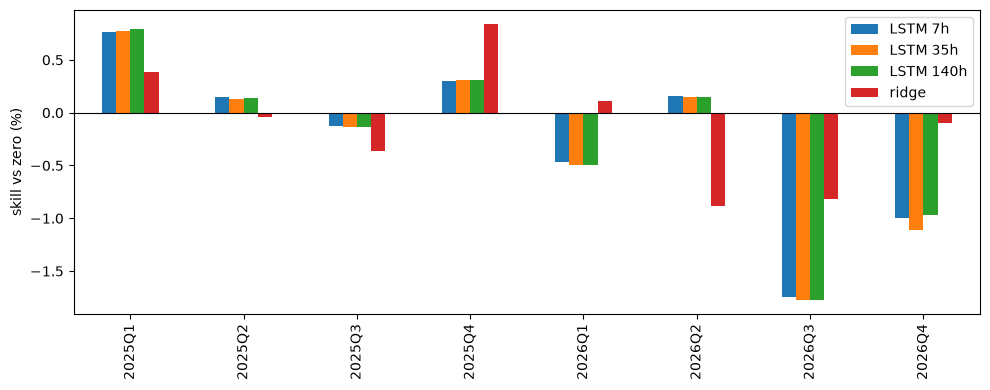

In [6]:
per_q = pd.DataFrame({
    name: report(base, p)["skill vs zero %"] for name, p in preds.items() if name != "zero"
}).drop("all")
ax = per_q.plot.bar(figsize=(10, 4))
ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel("skill vs zero (%)")
plt.tight_layout()

## Cumulative advantage over zero

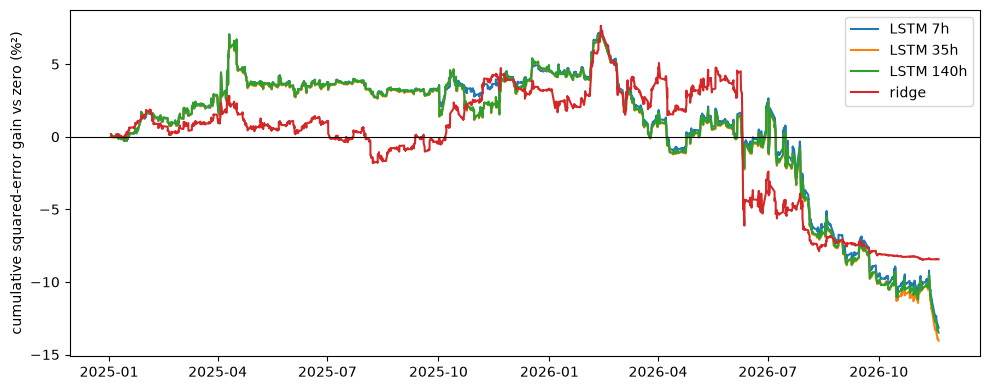

In [7]:
ts = base.timestamps
fig, ax = plt.subplots(figsize=(10, 4))
for name, p in preds.items():
    if name == "zero":
        continue
    gain = (y[p.index] ** 2 - (y[p.index] - p.to_numpy()) ** 2) * 1e4
    ax.plot(ts[p.index], np.cumsum(gain), label=name)
ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel("cumulative squared-error gain vs zero (%²)")
ax.legend()
plt.tight_layout()

## How bold are the predictions?
From notebook 03: with a weak signal, the safe prediction is a small one. Compare the spread of predictions.

In [8]:
pd.Series({name: p.std() * 100 for name, p in preds.items()}, name="prediction std (%)").round(3)

LSTM 7h      0.059
LSTM 35h     0.064
LSTM 140h    0.064
zero         0.000
ridge        0.053
Name: prediction std (%), dtype: float64

## Why do all windows give the same result?
The 7h, 35h and 140h models score almost identically per quarter. Test: take the trained 140-hour model,
replace the **older** part of each window by an "average hour" (the training mean), and see if predictions change.

In [9]:
import torch

train, test = splits[6]
m = LSTMRegressor(seed=0).fit(data[140].X[train], data[140].y[train])
X_test = data[140].X[test]
full = m.predict(X_test)

rows = {}
for keep in [140, 35, 7, 3, 1]:
    X_cut = X_test.copy()
    X_cut[:, :-keep, :] = m.x_mean       # wipe everything older than `keep` hours
    cut = m.predict(X_cut)
    rows[f"keep last {keep}h"] = {
        "corr with full window": np.corrcoef(full, cut)[0, 1],
        "max change (%)": np.abs(full - cut).max() * 100,
    }
display(pd.DataFrame(rows).T.round(4))

# PyTorch stores the 4 gates stacked as [input, forget, cell, output]
H = m.hidden
bias = (m.net.lstm.bias_ih_l0 + m.net.lstm.bias_hh_l0).detach()
forget = torch.sigmoid(bias[H:2 * H]).mean().item()
print(f"forget gate (for an average hour): {forget:.2f}")
print(f"share of memory left after 7h: {forget**7:.4f},  after 35h: {forget**35:.1e}")

,corr with full window,max change (%)
keep last 140h,1.0000,0.0000
keep last 35h,1.0000,0.0000
keep last 7h,0.9988,0.0271
keep last 3h,0.9680,0.1085
keep last 1h,0.7853,0.2400


forget gate (for an average hour): 0.50
share of memory left after 7h: 0.0077,  after 35h: 2.7e-11


**What it shows:** wiping everything older than 7 hours barely changes the 140-hour model's predictions (corr ≈ 1.00),
and older than 35 hours changes nothing at all. The model effectively looks at the last ~3–7 hours only.

**Why:** the **forget gate** decides how much of the memory cell survives each hour. It's still ≈ 0.5, which is
exactly where it started (a sigmoid of ~0). So the memory halves every hour: after 7 hours 0.8% is left, after 35 hours
nothing. Training only changes the forget gate if remembering longer *reduces the loss*. There's no long-range signal in
the data, so nothing pushes it up, and the 140-hour window is effectively a 7-hour window.

A common trick is to **start the forget-gate bias at 1 or higher** (sigmoid(1) ≈ 0.73), so the model begins with a longer
memory and has to learn to forget. Worth trying in step 5, but it can't create signal that isn't in the data.

## Conclusions (2026-11-20)

1. **The LSTM doesn't beat zero either.** Overall skill about −0.3% for every window. 2025: +0.23%, 2026: −0.7%.
   That's the same regime flip as ridge, and slightly worse overall than ridge on these hours (−0.19%).
2. **Window length makes no difference.** The forget gate stays at 0.5, so the model only uses the last ~3–7 hours,
   whatever we feed it.
3. **Seed luck is bigger than the window effect.** Per-seed skill ranges from −0.24% to −0.51%, while windows differ by
   ~0.02%. Averaging the 3 seeds lands in the middle of that range. Without several seeds we could have "found" a best
   window that was pure luck.
4. **Classic overfitting in the training curves.** Training loss keeps falling, validation stays at ~0.99 × zero. Early
   stopping keeps predictions small (std ~0.06%), which is why the damage stays small.
5. **Some quarters look good** (2025Q1 +0.8%), **others bad** (2026Q3 −1.8%). Any single quarter would be misleading.

Note: ridge scores −0.19% here vs −0.09% in notebook 03. All models here start later, because the 140-hour window needs more
history, so they have less training data. That's why every model is compared on identical hours.

**Next (step 5):** look inside the LSTM. Write the cell from scratch and check it matches `nn.LSTM`, plot the gate activations
on real data, and try the forget-gate bias trick.